# Figure S2a
Fixation location probability on the directed cycle with $N=40$ vertices for $r=1.5$, $2$, $3$, and $5$, with the normal approximation, the mean of $H$ from the theorem, and the drift prediction.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from fixloc import style as S

d = json.load(open('data.json'))

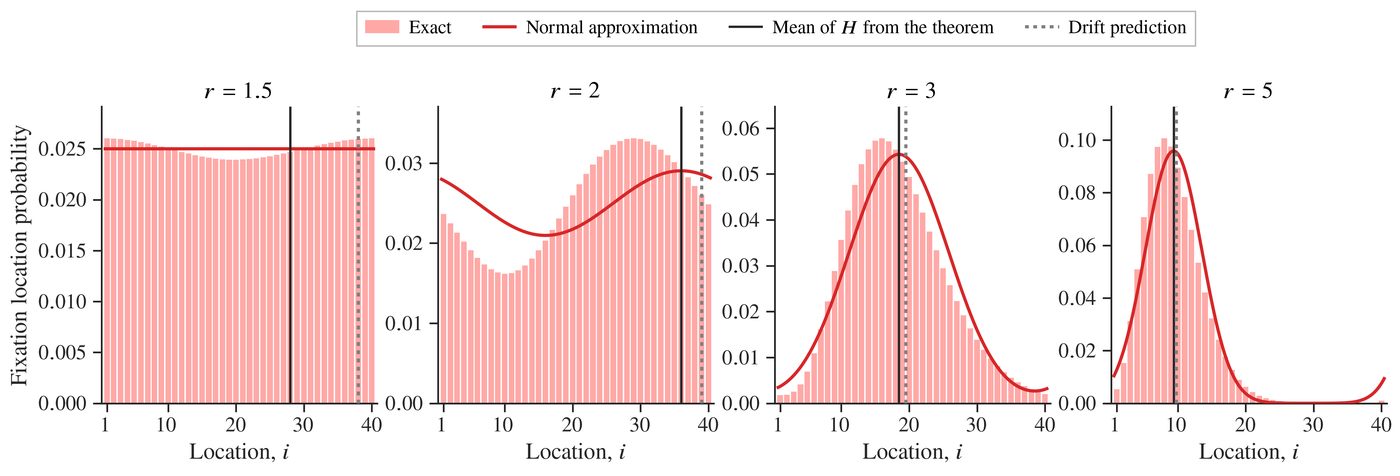

In [2]:
DOT = (0, (1.2, 1.4))
N = d['N']
xs = np.arange(1, N + 1)
xf = np.linspace(0.5, N + 0.5, 400)
fig = plt.figure(figsize=(7.0, 5.4))
for j, r in enumerate(d['rs']):
  c = d['curves'][str(r)]
  ax = fig.add_axes([0.075 + 0.232 * j, 0.635, 0.19, 0.265])
  ax.bar(xs, c['prob'], width=0.82, color=S.CM_LAST(0.42), lw=0, zorder=1)
  mu, sd = 1 + c['center'], c['sd_formula']
  dens = sum(np.exp(-0.5 * ((xf - mu + k * N) / sd) ** 2) for k in range(-4, 5)) / (sd * np.sqrt(2 * np.pi))
  ax.plot(xf, dens, color=S.RED, lw=1.1, zorder=3)
  ax.axvline(1 + c['center'], color=S.INK, lw=0.8, zorder=4)
  ax.axvline(1 + c['drift'], color=S.GRAY, lw=1.1, ls=DOT, zorder=4)
  ax.set_xlim(0.2, N + 0.8)
  ax.set_xticks([1, 10, 20, 30, 40])
  ax.set_ylim(0, max(max(c['prob']), dens.max()) * 1.12)
  ax.set_xlabel(r'Location, $i$')
  ax.set_title(r'$r=%g$' % r, pad=3)
  if j == 0:
    ax.set_ylabel('Fixation location probability')
ha = [
  Patch(color=S.CM_LAST(0.42), lw=0, label='Exact'),
  Line2D([], [], color=S.RED, lw=1.1, label='Normal approximation'),
  Line2D([], [], color=S.INK, lw=0.8, label=r'Mean of $H$ from the theorem'),
  Line2D([], [], color=S.GRAY, lw=1.1, ls=DOT, label='Drift prediction'),
]
lg = fig.legend(
  handles=ha,
  loc='upper center',
  bbox_to_anchor=(0.54, 0.995),
  ncol=4,
  fontsize=6.6,
  handlelength=1.8,
  columnspacing=1.6,
)
lg.get_frame().set_linewidth(0.5)
S.save_panel(fig, 'a', box=(0.005, 0.57, 0.97, 0.995))